<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%A08_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [3]:
iris = load_iris(as_frame=True)
df_iris = iris.data
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

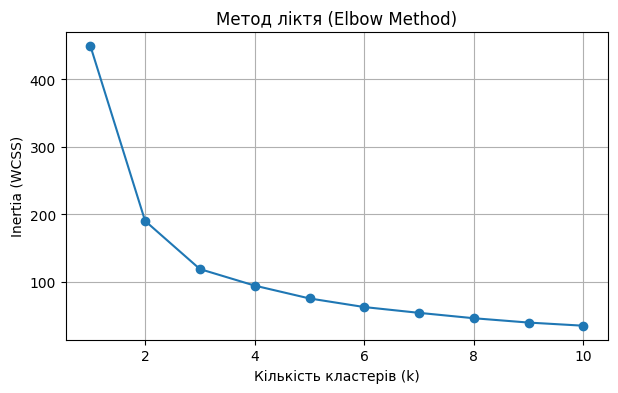

In [8]:
X_iris_3 = df_iris.iloc[:, :3]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_iris_3)
inertia = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
plt.figure(figsize=(7, 4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Inertia (WCSS)')
plt.title('Метод ліктя (Elbow Method)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

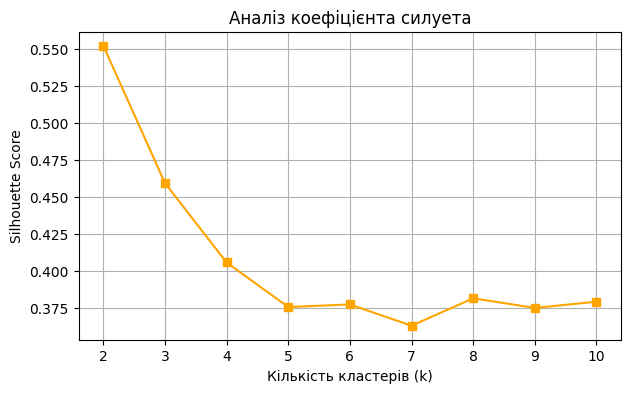

In [7]:
silhouette_scores = []
K_range_sil = range(2, 11)
for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
plt.figure(figsize=(7, 4))
plt.plot(K_range_sil, silhouette_scores, marker='s', color='orange')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Silhouette Score')
plt.title('Аналіз коефіцієнта силуета')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

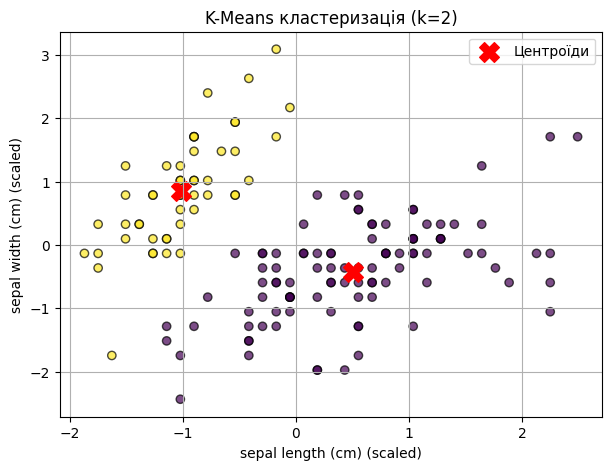

In [9]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_scaled)
centroids = kmeans_final.cluster_centers_
plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=cluster_labels, cmap='viridis', alpha=0.7, edgecolors='k')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', label='Центроїди')
plt.xlabel(f"{X_iris_3.columns[0]} (scaled)")
plt.ylabel(f"{X_iris_3.columns[1]} (scaled)")
plt.title('K-Means кластеризація (k=2)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:**

Графік ліктя показує найсильніший злам саме на 2 кластерах, де різко падає інерція (з 450 до менш ніж 200). Аналіз силуета це підтверджує: для $k = 2$ коефіцієнт найвищий (понад 0.55), а з кожним наступним кластером якість лише падає. Тому вибір двох кластерів є оптимальним — у даних ірисів один вид чітко відділений від інших, тоді як решта два дуже змішані між собою.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [12]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [13]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [15]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [16]:
print('Кількість дублікатів:', df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [17]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [18]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Розмір тренувальної вибірки:', X_train_scaled.shape)
print('Розмір тестової вибірки:', X_test_scaled.shape)

Розмір тренувальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [19]:
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)
best_rf = rf_grid.best_estimator_
test_acc = best_rf.score(X_test_scaled, y_test)
print('Найкращі параметри:', rf_grid.best_params_)
print(f'Середня CV точність: {rf_grid.best_score_:.4f}')
print(f'Тестова accuracy: {test_acc:.4f}')

Найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Середня CV точність: 0.9190
Тестова accuracy: 0.9123


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [20]:
param_grid_lr = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'solver': ['saga'],
    'max_iter': [1000]
}
lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)
best_lr = lr_grid.best_estimator_
test_acc_lr = best_lr.score(X_test_scaled, y_test)
print('Найкращі параметри:', lr_grid.best_params_)
print(f'Середня CV точність: {lr_grid.best_score_:.4f}')
print(f'Тестова accuracy: {test_acc_lr:.4f}')

Найкращі параметри: {'C': 10.0, 'max_iter': 1000, 'solver': 'saga'}
Середня CV точність: 0.7951
Тестова accuracy: 0.7933


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [21]:
param_grid_svm = {
    'C': [0.1, 1.0, 10.0],
    'kernel': ['linear', 'rbf']
}
svm_grid = GridSearchCV(
    SVC(random_state=42),
    param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)
best_svm = svm_grid.best_estimator_
test_acc_svm = best_svm.score(X_test_scaled, y_test)
print('Найкращі параметри:', svm_grid.best_params_)
print(f'Середня CV точність: {svm_grid.best_score_:.4f}')
print(f'Тестова accuracy: {test_acc_svm:.4f}')

Найкращі параметри: {'C': 10.0, 'kernel': 'linear'}
Середня CV точність: 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [22]:
models_summary = {
    'Random Forest': (rf_grid.best_score_, test_acc, best_rf),
    'Logistic Regression': (lr_grid.best_score_, test_acc_lr, best_lr),
    'Support Vector Machine': (svm_grid.best_score_, test_acc_svm, best_svm)
}
comparison_df = pd.DataFrame([
    {'Model': name, 'CV Accuracy': scores[0], 'Test Accuracy': scores[1]}
    for name, scores in models_summary.items()
]).sort_values(by='CV Accuracy', ascending=False).reset_index(drop=True)
display(comparison_df)
best_model_name = max(models_summary, key=lambda k: models_summary[k][0])
best_overall_model = models_summary[best_model_name][2]
print(f"\nНайкраща модель за CV точністю: {best_model_name}")
y_pred_best = best_overall_model.predict(X_test_scaled)
print("\nЗвіт класифікації (classification_report) для найкращої моделі:")
print(classification_report(y_test, y_pred_best, digits=4))

,Model,CV Accuracy,Test Accuracy
0,Random Forest,0.918982,0.912317
1,Support Vector Machine,0.852065,0.858038
2,Logistic Regression,0.795084,0.793319



Найкраща модель за CV точністю: Random Forest

Звіт класифікації (classification_report) для найкращої моделі:
              precision    recall  f1-score   support

         0.0     1.0000    0.2857    0.4444        21
         1.0     0.8246    0.8704    0.8468        54
         2.0     0.9024    0.9487    0.9250        78
         3.0     0.8916    0.8916    0.8916        83
         4.0     0.9402    0.9712    0.9555       243

    accuracy                         0.9123       479
   macro avg     0.9118    0.7935    0.8127       479
weighted avg     0.9152    0.9123    0.9048       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

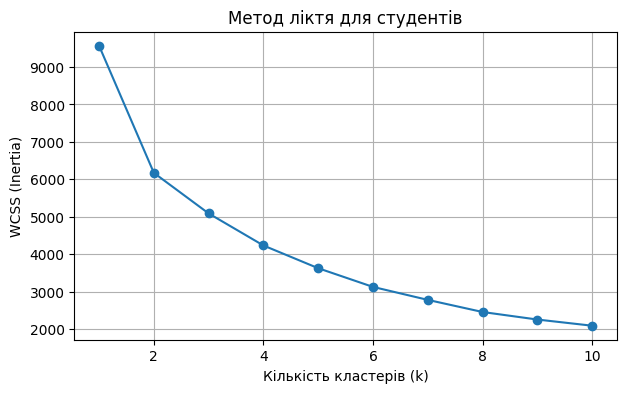

In [23]:
features_students = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud_scaled = StandardScaler().fit_transform(df[features_students])
inertia_stud = []
K_stud_range = range(1, 11)
for k in K_stud_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_stud_scaled)
    inertia_stud.append(km.inertia_)
plt.figure(figsize=(7, 4))
plt.plot(K_stud_range, inertia_stud, marker='o')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.title('Метод ліктя для студентів')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

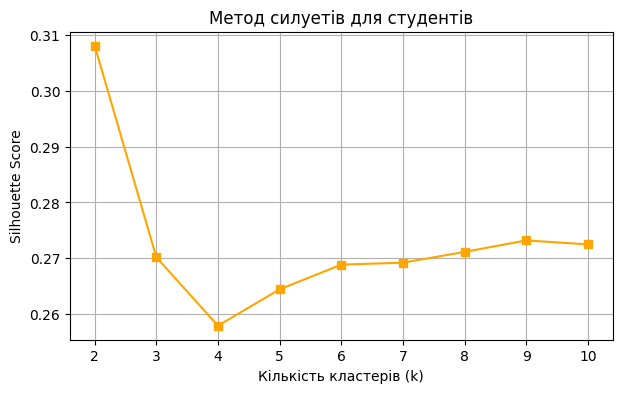

In [24]:
sil_scores_stud = []
K_sil_stud_range = range(2, 11)
for k in K_sil_stud_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_stud_scaled)
    sil_scores_stud.append(silhouette_score(X_stud_scaled, labels))
plt.figure(figsize=(7, 4))
plt.plot(K_sil_stud_range, sil_scores_stud, marker='s', color='orange')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Silhouette Score')
plt.title('Метод силуетів для студентів')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [25]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [26]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [27]:
X_pca_raw = df.drop(columns=['StudentID', 'GradeClass'])
print('Кількість ознак для PCA:', X_pca_raw.shape[1])

Кількість ознак для PCA: 13


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [29]:
X_pca_scaled = StandardScaler().fit_transform(X_pca_raw)
pca = PCA()
pca.fit(X_pca_scaled)
explained_variance = pca.explained_variance_ratio_
print('Частка дисперсії кожної компоненти:\n', np.round(explained_variance, 4))

Частка дисперсії кожної компоненти:
 [0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

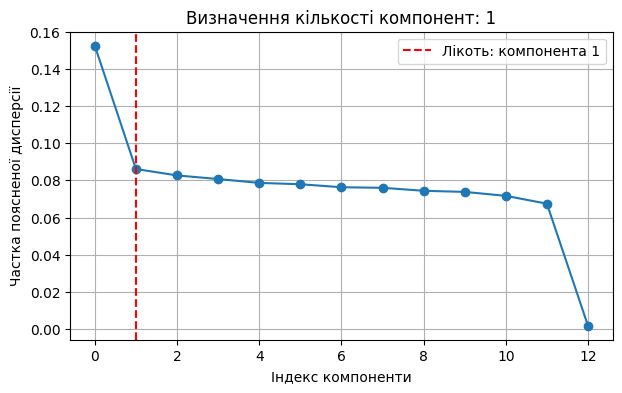

Знайдений індекс компоненти ліктя: 1


In [30]:
x_comp = range(len(explained_variance))
kneedle = KneeLocator(x_comp, explained_variance, curve='convex', direction='decreasing')
best_comp_idx = kneedle.elbow
plt.figure(figsize=(7, 4))
plt.plot(x_comp, explained_variance, marker='o')
if best_comp_idx is not None:
    plt.axvline(x=best_comp_idx, color='r', linestyle='--', label=f'Лікоть: компонента {best_comp_idx}')
plt.xlabel('Індекс компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.title(f'Визначення кількості компонент: {best_comp_idx}')
plt.legend()
plt.grid(True)
plt.show()
print('Знайдений індекс компоненти ліктя:', best_comp_idx)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

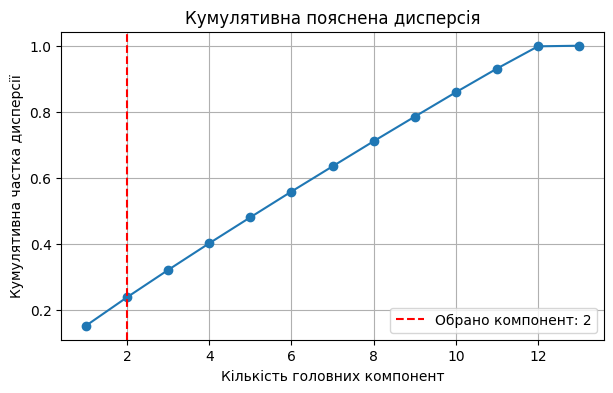

Кількість обраних компонент: 2
Фактична частка кумулятивної дисперсії: 0.2386


In [31]:
cumulative_variance = np.cumsum(explained_variance)
n_components = best_comp_idx + 1
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axvline(x=n_components, color='r', linestyle='--', label=f'Обрано компонент: {n_components}')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.title('Кумулятивна пояснена дисперсія')
plt.legend()
plt.grid(True)
plt.show()
actual_variance = cumulative_variance[n_components - 1]
print(f'Кількість обраних компонент: {n_components}')
print(f'Фактична частка кумулятивної дисперсії: {actual_variance:.4f}')
pca_final = PCA(n_components=n_components)
X_pca_transformed = pca_final.fit_transform(X_pca_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [32]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

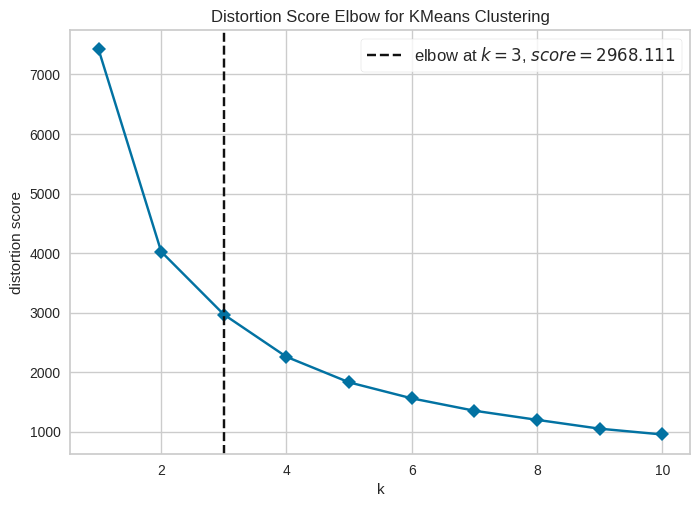

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [33]:
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10), k=(1, 11), timings=False)
visualizer.fit(X_pca_transformed)
visualizer.show()

## Висновки

У ході дослідження порівняно різні підходи до визначення кількості кластерів: для початкових чотирьох числових ознак метод силуетів показав пік при $k = 2$ ($\approx 0.307$), тоді як графік ліктя WCSS демонстрував плавне спадання. Після переходу до всіх ознак і зниження розмірності через PCA автоматичний візуалізатор KElbowVisualizer визначив чітку точку зламу при $k = 3$ зі значенням distortion score $2968.111$.

Різниця між класифікацією та кластеризацією полягає в типі навчання: класифікація є навчанням із учителем (supervised learning), де моделі спираються на мітку GradeClass для оптимізації розділових меж, досягаючи точності до $91.23\%$ на тесті (Random Forest). На противагу цьому, кластеризація (unsupervised learning) групує студентів суто за внутрішньою схожістю профілів ознак без прив'язки до їхнього підсумкового академічного класу, виявляючи приховані паттерни поведінки.

За допомогою аналізу точкового перегину частки поясненої дисперсії (KneeLocator, індекс 1) було обрано 2 головні компоненти. Вони сумарно пояснюють $0.2386$ ($23.86\%$) загальної дисперсії вибірки, що дозволило суттєво стиснути простір із 13 ознак до двовимірного представлення для подальшої стабільної кластеризації.